In [ ]:
#Create Dataset

In [1]:
import pandas as pd

data = {
    "temperature": [18, 20, 22, 24, 26, 28, 30, 32, 25, 21, 27, 29],
    "humidity": [80, 75, 72, 68, 65, 60, 55, 50, 70, 78, 62, 58],
    "wind_speed": [2, 3, 4, 5, 6, 7, 8, 9, 4, 2, 6, 7],
    "traffic_density": [90, 85, 80, 75, 70, 65, 55, 45, 78, 88, 68, 60],
    "pollution": [190, 180, 168, 155, 145, 130, 110, 95, 160, 185, 135, 120]
}

df = pd.DataFrame(data)

df

,temperature,humidity,wind_speed,traffic_density,pollution
0,18,80,2,90,190
1,20,75,3,85,180
2,22,72,4,80,168
3,24,68,5,75,155
4,26,65,6,70,145
5,28,60,7,65,130
6,30,55,8,55,110
7,32,50,9,45,95
8,25,70,4,78,160
9,21,78,2,88,185


In [ ]:
#Separate X and y

In [2]:
X = df[
    [
        "temperature",
        "humidity",
        "wind_speed",
        "traffic_density"
    ]
]

y = df["pollution"]

print("Features:")
print(X)

print("\nTarget:")
print(y)

Features:
    temperature  humidity  wind_speed  traffic_density
0            18        80           2               90
1            20        75           3               85
2            22        72           4               80
3            24        68           5               75
4            26        65           6               70
5            28        60           7               65
6            30        55           8               55
7            32        50           9               45
8            25        70           4               78
9            21        78           2               88
10           27        62           6               68
11           29        58           7               60

Target:
0     190
1     180
2     168
3     155
4     145
5     130
6     110
7      95
8     160
9     185
10    135
11    120
Name: pollution, dtype: int64


In [ ]:
#Split the data

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 9
Testing samples: 3


In [ ]:
#Train our first model

In [4]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training complete!")

Model training complete!


In [ ]:
#Make predictions

In [5]:
predictions = model.predict(X_test)

results = pd.DataFrame({
    "Actual Pollution": y_test.values,
    "Predicted Pollution": predictions.round(2)
})

results

,Actual Pollution,Predicted Pollution
0,135,139.65
1,185,173.49
2,190,173.49


In [ ]:
#Evaluate it

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.2f}")

MAE:  10.89
RMSE: 11.93
R²:   0.77


In [ ]:
#feature importance
Which environmental factors are influencing the model's pollution predictions?

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
1,humidity,0.287683
0,temperature,0.263881
2,wind_speed,0.225784
3,traffic_density,0.222651


In [ ]:
#first model interpretation visualization.

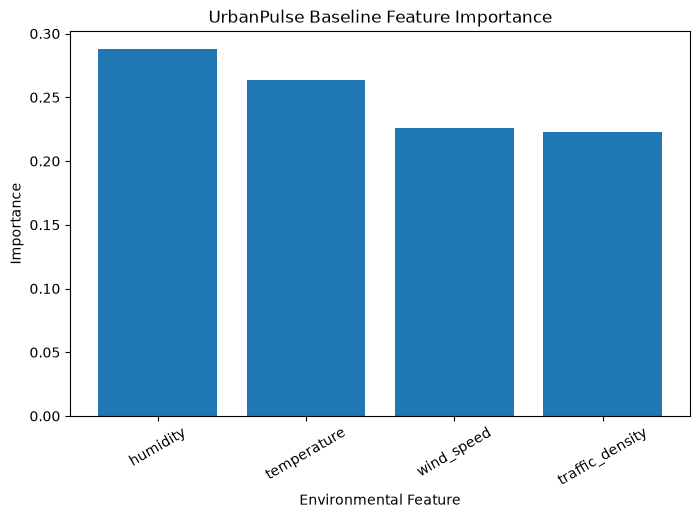

In [8]:
plt.figure(figsize=(8, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Environmental Feature")
plt.ylabel("Importance")
plt.title("UrbanPulse Baseline Feature Importance")

plt.xticks(rotation=30)

plt.show()

In [ ]:
#first model benchmarking experiment

In [10]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print(f"Linear Regression MAE:  {linear_mae:.2f}")
print(f"Linear Regression RMSE: {linear_rmse:.2f}")
print(f"Linear Regression R²:   {linear_r2:.2f}")

Linear Regression MAE:  2.24
Linear Regression RMSE: 3.15
Linear Regression R²:   0.98


In [ ]:
#final comparison cell
This is the first tiny model evaluation table

In [11]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        linear_mae,
        mae
    ],
    "RMSE": [
        linear_rmse,
        rmse
    ],
    "R²": [
        linear_r2,
        r2
    ]
})

comparison

,Model,MAE,RMSE,R²
0,Linear Regression,2.24191,3.147361,0.983936
1,Random Forest,10.89000,11.925920,0.769361
